## Exploratory Data Analysis
### DSCI 403
#### Clara Pugh and Chandler Bergstrom

This notebook loads in preprocessed data saved using preprocessing.ipynb, and investigates patterns using summary statistics and visualizations

In [1]:
# we should start with some summary statistics of the dataframe
# then make some plots:
    # sea surface temperature measured by ARGO vs by satellite (2D map of satellite SST with points of ARGO temp on top?)
    # temperature with depth of a few individual ARGO profiles
    # sea surface temperature as a function of time?? I'm not sure how useful that would be

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [52]:
# load in the preprocessed data that we saved
full_df = pd.read_csv('clean_data_gulfstream_jan_2023.csv')
full_df['TIME'] = pd.to_datetime(full_df['TIME'])

surface_df = pd.read_csv('clean_SURFACE_data_gulfstream_jan_2023.csv')
surface_df['TIME'] = pd.to_datetime(surface_df['TIME'])

# as well as the full SST dataframe
sst_df = pd.read_csv('SST_only_gulfstream_jan_2023_not_clean.csv')

sst_df.head()

,time,zlev,latitude,longitude,sst,anom,err,ice
0,2023-01-01 12:00:00,0.0,25.125,-79.625,26.97,1.99,0.13,NaN
1,2023-01-01 12:00:00,0.0,25.125,-79.375,26.51,1.46,0.13,NaN
2,2023-01-01 12:00:00,0.0,25.125,-79.125,25.08,0.00,0.12,NaN
3,2023-01-01 12:00:00,0.0,25.125,-78.875,23.63,-1.49,0.12,NaN
4,2023-01-01 12:00:00,0.0,25.125,-78.625,23.16,-1.99,0.12,NaN


In [53]:
# .info() gives data type and non-null count for each column, and memory usage for the dataframe
print('data types, non-null counts, memory usage for full dataframe:\n')
print(full_df.info())

# .describe() gives some summary statistics to explore the data
print('\nsummary statistics for numeric columns of full dataframe:\n')
print(full_df.describe())

data types, non-null counts, memory usage for full dataframe:

<class 'pandas.DataFrame'>
RangeIndex: 97145 entries, 0 to 97144
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   index            97145 non-null  int64         
 1   N_PROF           97145 non-null  int64         
 2   N_LEVELS         97145 non-null  int64         
 3   CYCLE_NUMBER     97145 non-null  int64         
 4   DATA_MODE        97145 non-null  str           
 5   DIRECTION        97145 non-null  str           
 6   PLATFORM_NUMBER  97145 non-null  int64         
 7   PRES             97145 non-null  float64       
 8   PRES_ERROR       70420 non-null  float64       
 9   PSAL             97145 non-null  float64       
 10  PSAL_ERROR       70420 non-null  float64       
 11  TEMP             97145 non-null  float64       
 12  TEMP_ERROR       70420 non-null  float64       
 13  LATITUDE         97145 non-null  float6

In [54]:
# .info() gives data type and non-null count for each column, and memory usage for the dataframe
print('data types, non-null counts, memory usage for surface dataframe:\n')
print(surface_df.info())

# .describe() gives some summary statistics to explore the data
print('\nsummary statistics for numeric columns for surface dataframe:\n')
print(surface_df.describe())

data types, non-null counts, memory usage for surface dataframe:

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   PLATFORM_NUMBER  215 non-null    int64         
 1   CYCLE_NUMBER     215 non-null    int64         
 2   TIME             215 non-null    datetime64[us]
 3   LAT              215 non-null    float64       
 4   LON              215 non-null    float64       
 5   DATA_MODE        215 non-null    str           
 6   TEMP_SURF        215 non-null    float64       
 7   SST              215 non-null    float64       
 8   DIST_KM          215 non-null    float64       
 9   N_OBS            215 non-null    int64         
 10  DIFF             215 non-null    float64       
 11  OUTLIER          215 non-null    bool          
dtypes: bool(1), datetime64[us](1), float64(6), int64(3), str(1)
memory usage: 18.8 KB
None

summa

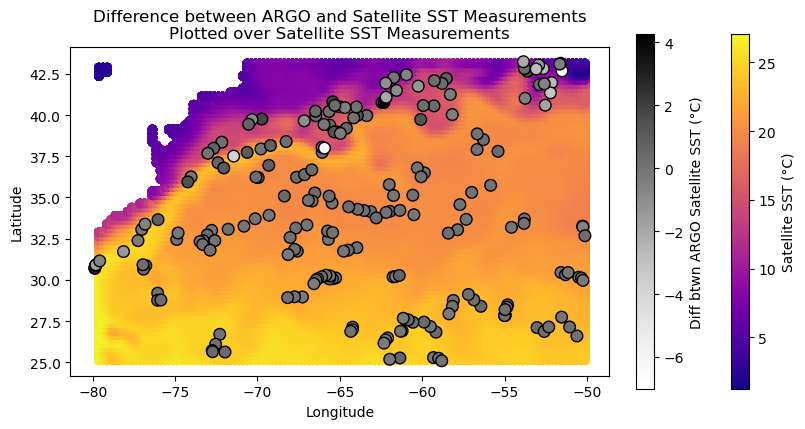

In [55]:
# plot two plots: Argo - satellite SST on spatial grid, and satellite SST on grid

fig, ax = plt.subplots(1,1,figsize=(8,6), layout='constrained')

# plot satellite SST
sst = ax.scatter(sst_df['longitude'], sst_df['latitude'], c=sst_df['sst'], cmap='plasma')
fig.colorbar(sst, ax=ax, label='Satellite SST (°C)', shrink=0.6)

# plot differences between temps
diffs = ax.scatter(surface_df['LON'], surface_df['LAT'], c=surface_df['DIFF'], cmap='Greys',s=70,edgecolors='black')
fig.colorbar(diffs, ax=ax, label='Diff btwn ARGO Satellite SST (°C)', shrink=0.6)

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Difference between ARGO and Satellite SST Measurements\nPlotted over Satellite SST Measurements')

ax.set_aspect('equal', adjustable='box')